<a href="https://colab.research.google.com/github/QASIMkhan1212/Ai-Engineering/blob/main/Ai_Engineering_part_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 3 · Unit 1.3 — Beyond Text: Images, Audio and PDFs

**Mental model:** `Image / audio / PDF → converted into tokens → model reads them → answers in text`

**Goal of today:** choose when to send images, audio or documents to a model, predict what each will cost, and know where each one may go wrong.

**How to use this notebook:** read Part 1, then run the experiments top to bottom in Google Colab. You need a free **Gemini API key** (saved in Colab Secrets as `GEMINI_API_KEY`). Experiment 4 also uses your **Groq key** (`GROQ_API_KEY`) for speech-to-text. After each experiment, read the "What to look for" box.

## Part 1 — The 7 ideas in simple words

### 1. Models that see and hear
Many modern models accept **images, audio and documents** as well as text. They still **answer in text**. You pass the file together with your question, for example "What is the total on this invoice?".

### 2. Images cost tokens too
An image is converted into tokens, just like text.
- **Bigger / higher-resolution image → usually more tokens** (on many providers the count grows in steps).
- You pay for the image **on every request** that includes it.
- So **crop or resize** to what the question needs. A tiny logo does not need a 4000-pixel photo.

### 3. PDFs come in two kinds
| Kind | What it is | How to tell |
|---|---|---|
| **Digital PDF** | Has real text inside (made from Word, a website, a system) | You can select and copy the text |
| **Scanned PDF** | Just a **picture of each page** | Text extraction gives nothing (empty) |

A scanned PDF has to be read like an image (or OCR'd first), so it is slower, costs more, and is more error-prone.

### 4. Audio
Two ways to use speech:
1. **Transcribe first:** speech-to-text, then send the **text** to a model. Cheap, searchable, easy to check. But **tone and emphasis are lost**.
2. **Send the audio directly** to a model that understands audio. It can keep tone, emotion and emphasis, but it is usually more costly and harder to inspect.

### 5. What models read well
- **Text inside images** (signs, screenshots, documents)
- **The main point of a chart** (which bar is highest, the trend)
- **Named fields on forms** (invoice number, date, total)

### 6. Where they slip
- **Counting** objects
- **Small or dense text**
- **Exact numbers** from tables or charts (they estimate)
- **Confidently describing details that are not really there** (hallucination, same as Unit 1.1)

### 7. Image or extracted text?
- If **clean text is available**, send the text. It is usually **cheaper and more accurate**.
- Send the **image** when **layout, charts or handwriting** matter and text extraction would lose information.

## Setup

In [1]:
!pip -q install google-genai pillow matplotlib pymupdf fpdf2 gTTS openai pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.8/88.8 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 MB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 341.3/341.3 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 41.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.


In [2]:
import io, time, random
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Audio, display
from google import genai
from google.genai import types
from openai import OpenAI

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

# Keys come from Colab Secrets (key icon in the left sidebar). Never type keys into the notebook.
try:
    from google.colab import userdata
    gem = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
    print("Gemini client ready")
except Exception as e:
    gem = None
    print("No Gemini client:", e)

try:
    groq = OpenAI(api_key=userdata.get("GROQ_API_KEY"), base_url="https://api.groq.com/openai/v1")
    print("Groq client ready (used only for speech-to-text)")
except Exception as e:
    groq = None
    print("No Groq client (Experiment 4 transcription part will be skipped):", e)

MODEL = "gemini-2.5-flash"   # if you get a 'model not found' error, run the next cell and pick a current one

No Gemini client: Requesting secret GEMINI_API_KEY timed out. Secrets can only be fetched when running from the Colab UI.
No Groq client (Experiment 4 transcription part will be skipped): Requesting secret GROQ_API_KEY timed out. Secrets can only be fetched when running from the Colab UI.


In [3]:
# Optional: list available Gemini models if MODEL above gives an error
if gem:
    print([m.name for m in gem.models.list() if "flash" in m.name][:15])

In [4]:
def ask(parts, question, retries=3):
    # Send parts (images, PDFs, audio, text) + a question. Returns the answer and token usage.
    for attempt in range(retries):
        try:
            r = gem.models.generate_content(
                model=MODEL,
                contents=list(parts) + [question],
                config=types.GenerateContentConfig(
                    temperature=0,
                    system_instruction="Answer in one short sentence. If something is not visible or not present, say so."),
            )
            u = r.usage_metadata
            return {"answer": (r.text or "").strip(),
                    "input_tokens": u.prompt_token_count,
                    "output_tokens": u.candidates_token_count or 0,
                    "thinking_tokens": getattr(u, "thoughts_token_count", 0) or 0}
        except Exception as e:
            if attempt == retries - 1:
                return {"answer": "ERROR: " + str(e)[:100], "input_tokens": None,
                        "output_tokens": None, "thinking_tokens": None}
            time.sleep(6 * (attempt + 1))

def count_tokens(parts):
    return gem.models.count_tokens(model=MODEL, contents=list(parts)).total_tokens

INPUT_PRICE_PER_M = 0.30    # EXAMPLE price, USD per 1M input tokens -> replace with your model's real price
CALLS = 10_000
def input_cost(tokens, calls=CALLS):
    return calls * tokens * INPUT_PRICE_PER_M / 1_000_000

## Experiment 1 — The same chart as an image vs as extracted text
*(This is the official "Try it" for today.)*

**What this code does**
1. Draws a bar chart of monthly sales (Jan to Jun) and saves it as an image. **The bars have no number labels on purpose**, so exact values must be estimated from the picture.
2. Makes a **text version** of the same chart (the underlying numbers, like you would get from extracting data).
3. Asks **the same 3 questions** to both versions and compares the **answers** and the **input tokens**.

The 3 questions: (1) the main point, (2) an exact value, (3) a calculation.

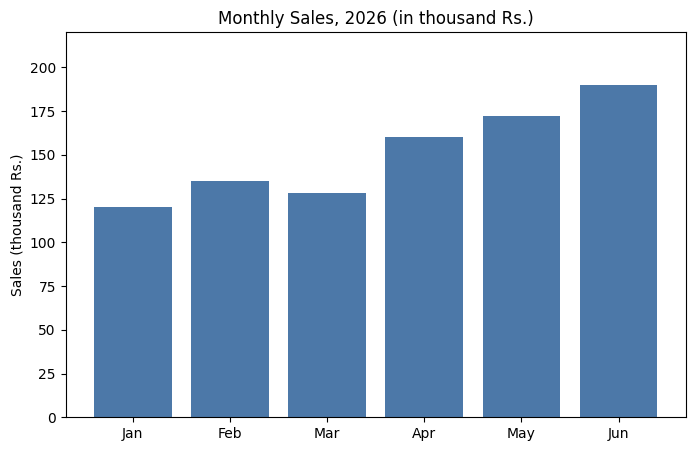

Image size: (2087, 1349)
Chart: Monthly Sales, 2026 (in thousand Rs.)
Month, Sales
Jan, 120
Feb, 135
Mar, 128
Apr, 160
May, 172
Jun, 190


In [5]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales  = [120, 135, 128, 160, 172, 190]

def make_chart(show_labels=False, dpi=300, path="chart.png"):
    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(months, sales, color="#4C78A8")
    ax.set_title("Monthly Sales, 2026 (in thousand Rs.)")
    ax.set_ylabel("Sales (thousand Rs.)")
    ax.set_ylim(0, 220)
    if show_labels:
        ax.bar_label(bars)      # set show_labels=True to print the numbers on the bars
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.show()
    plt.close(fig)

make_chart(show_labels=False)
chart_img = Image.open("chart.png").convert("RGB")
print("Image size:", chart_img.size)

chart_text = ("Chart: Monthly Sales, 2026 (in thousand Rs.)\n"
              "Month, Sales\n" + "\n".join(f"{m}, {s}" for m, s in zip(months, sales)))
print(chart_text)

In [6]:
questions = [
    ("Which month had the highest sales?", "Jun"),
    ("What were the exact sales in March (in thousand Rs.)?", "128"),
    ("By what percent did sales grow from January to June? Give one number.", "58.3%"),
]

rows = []
for q, truth in questions:
    a = ask([chart_img], q)
    b = ask([chart_text], q)
    rows.append({"question": q, "correct answer": truth,
                 "IMAGE answer": a["answer"], "image in-tokens": a["input_tokens"],
                 "TEXT answer": b["answer"], "text in-tokens": b["input_tokens"]})
res1 = pd.DataFrame(rows)
display(res1)

,question,correct answer,IMAGE answer,image in-tokens,TEXT answer,text in-tokens
0,Which month had the highest sales?,Jun,ERROR: 'NoneType' object has no attribute 'models',None,ERROR: 'NoneType' object has no attribute 'models',None
1,What were the exact sales in March (in thousand Rs.)?,128,ERROR: 'NoneType' object has no attribute 'models',None,ERROR: 'NoneType' object has no attribute 'models',None
2,By what percent did sales grow from January to June? Give one number.,58.3%,ERROR: 'NoneType' object has no attribute 'models',None,ERROR: 'NoneType' object has no attribute 'models',None


### What to look for
- **Tokens:** the image version should use **many more input tokens** than the text version, and you pay that again on every question.
- **Q1 (main point):** the image should be fine.
- **Q2 (exact value):** with no labels on the bars, the image answer is an *estimate* (it may say about 125 or 130). The text version gives exactly 128.
- **Q3 (calculation):** compare both. If the image gave a wrong percent, it is because the values it read were slightly off.
- Now set `make_chart(show_labels=True)` and re-run: printed numbers on the bars should make Q2 much easier. This shows **text inside images is read well, estimated bar heights are not**.

## Experiment 2 — Image size vs token cost
**What this code does:** shrinks the same chart to different widths (and also crops it), counts the tokens for each, and shows what it would cost to send each one 10,000 times. Then it checks whether a smaller image still answers correctly.

> The price is an **example number only**. Replace it with the real price of your model.

In [ ]:
def resize_to_width(img, w):
    h = int(img.height * w / img.width)
    return img.resize((w, h))

variants = {f"{w}px wide": resize_to_width(chart_img, w) for w in [150, 300, 600, 1200, 2000]}
variants["right half only (crop)"] = chart_img.crop((chart_img.width // 2, 0, chart_img.width, chart_img.height))

rows = []
for name, im in variants.items():
    t = count_tokens([im])
    rows.append({"version": name, "size": im.size, "tokens": t,
                 f"cost for {CALLS:,} sends ($)": round(input_cost(t), 4)})
t_text = count_tokens([chart_text])
rows.append({"version": "text version", "size": "-", "tokens": t_text,
             f"cost for {CALLS:,} sends ($)": round(input_cost(t_text), 4)})
display(pd.DataFrame(rows))

### Does shrinking hurt the answer?

In [ ]:
rows = []
for w in [150, 600, 2000]:
    im = resize_to_width(chart_img, w)
    for q, truth in questions[:2]:
        r = ask([im], q)
        rows.append({"width": w, "question": q, "correct": truth,
                     "answer": r["answer"], "input tokens": r["input_tokens"]})
display(pd.DataFrame(rows))

### What to look for
- Token count usually **grows with image size**, often in **steps** rather than smoothly. Some providers have a minimum, so tiny images may all cost the same.
- The **crop** is cheaper than the full chart. If the question is only about part of an image, crop it.
- The **text version** is by far the cheapest.
- In the accuracy table: the main point (Q1) often survives a small size, but readable details and exact numbers get worse. **Pick the smallest image that still answers your question**, and test it.

## Experiment 3 — Digital PDF vs scanned PDF
**What this code does**
1. Creates a small **digital** invoice PDF (real text inside).
2. Turns it into a **scanned-style** PDF (each page becomes a picture, no text inside).
3. Tries to **extract text** from both. Digital works, scanned returns nothing.
4. Sends the digital PDF, the scanned PDF, and the extracted text to the model, asks 3 questions about named fields, and compares answers and tokens.

In [ ]:
try:
    import pymupdf as fitz       # PyMuPDF
except ImportError:
    import fitz
from fpdf import FPDF

invoice_lines = [
    "INVOICE", "",
    "Invoice No: INV-2041",
    "Date: 12 October 2026",
    "Customer: Ali Traders, Karachi", "",
    "Item           Qty   Price   Amount",
    "Cotton shirt   10    250     2,500",
    "Denim jeans    4     590     2,360", "",
    "Total: Rs. 4,860",
    "Payment due: 26 October 2026",
]

pdf = FPDF()
pdf.add_page()
pdf.set_font("Courier", size=14)
for line in invoice_lines:
    pdf.cell(0, 9, line)
    pdf.ln(9)
digital_pdf = bytes(pdf.output())

def make_scanned(pdf_bytes, dpi=110):
    src = fitz.open(stream=pdf_bytes, filetype="pdf")
    out = fitz.open()
    for page in src:
        pix = page.get_pixmap(dpi=dpi)
        newp = out.new_page(width=page.rect.width, height=page.rect.height)
        newp.insert_image(newp.rect, stream=pix.tobytes("png"))
    return out.tobytes()

scanned_pdf = make_scanned(digital_pdf)

def extract_text(pdf_bytes):
    doc = fitz.open(stream=pdf_bytes, filetype="pdf")
    return "".join(page.get_text() for page in doc).strip()

digital_text = extract_text(digital_pdf)
scanned_text = extract_text(scanned_pdf)
print("Digital PDF  -> extracted characters:", len(digital_text))
print("Scanned PDF  -> extracted characters:", len(scanned_text), "(0 means it is just a picture)")
print("\nExtracted text from the digital PDF:\n" + digital_text)

def looks_scanned(pdf_bytes, min_chars_per_page=20):
    doc = fitz.open(stream=pdf_bytes, filetype="pdf")
    return len(extract_text(pdf_bytes)) < min_chars_per_page * len(doc)

print("\nlooks_scanned(digital):", looks_scanned(digital_pdf), "| looks_scanned(scanned):", looks_scanned(scanned_pdf))

In [ ]:
def pdf_part(b):
    return types.Part.from_bytes(data=b, mime_type="application/pdf")

pdf_questions = [
    ("What is the invoice number?", "INV-2041"),
    ("Who is the customer?", "Ali Traders, Karachi"),
    ("What is the total amount?", "Rs. 4,860"),
]
versions = {
    "digital PDF":    [pdf_part(digital_pdf)],
    "scanned PDF":    [pdf_part(scanned_pdf)],
    "extracted text": [digital_text],
}

rows = []
for q, truth in pdf_questions:
    for name, parts in versions.items():
        r = ask(parts, q)
        rows.append({"question": q, "correct": truth, "version": name,
                     "answer": r["answer"], "input tokens": r["input_tokens"]})
res3 = pd.DataFrame(rows)
display(res3)
display(res3.groupby("version")["input tokens"].mean().round(0).rename("avg input tokens"))

### What to look for
- **Extraction:** the digital PDF gives real text, the scanned one gives **0 characters**. This is how you can detect which kind you have (the `looks_scanned` function).
- **Named fields** (invoice number, customer, total) should be answered correctly by all three on this clean example.
- **Tokens:** extracted text is the cheapest. The PDFs cost more because the model also processes the **page itself**, not only the words.
- A real scan is **noisier** (blurry, tilted, shadows) than our clean one, so expect more mistakes on real scanned documents. Increase risk, not just cost.
- Rule: **digital PDF with clean text → extract the text and send that.** Scanned PDF → send as image (or OCR first).

## Experiment 4 — Audio: transcribe first, or send the audio directly?
**What this code does**
1. Makes a short voice message with text-to-speech.
2. **Path A:** transcribes it with Whisper on Groq, then sends only the **text** to the model.
3. **Path B:** sends the **audio itself** to the model.
4. Compares answers and tokens.

Note: transcription services are often billed by audio minutes or hours, not by tokens, so token counts alone do not tell the full cost story.

In [ ]:
from gtts import gTTS

speech_text = ("Hello, this is Ali from Karachi. I would like to cancel my order number 48213, "
               "because it arrived two weeks late. Please refund me by Friday.")
gTTS(speech_text, lang="en").save("sample.mp3")
display(Audio("sample.mp3"))
audio_bytes = open("sample.mp3", "rb").read()

# ---- Path A: speech-to-text first ----
transcript = None
if groq:
    tr = groq.audio.transcriptions.create(
        model="whisper-large-v3-turbo",
        file=("sample.mp3", audio_bytes),
        response_format="text")
    transcript = tr if isinstance(tr, str) else tr.text
    transcript = transcript.strip()
    print("Transcript:", transcript)
else:
    print("No Groq client, Path A skipped.")

audio_part = types.Part.from_bytes(data=audio_bytes, mime_type="audio/mp3")
q = "What order number is mentioned, and what does the caller want?"

rows = []
if transcript:
    a = ask([transcript], q)
    rows.append({"path": "A: transcript -> text", "answer": a["answer"], "input tokens": a["input_tokens"]})
b = ask([audio_part], q)
rows.append({"path": "B: audio sent directly", "answer": b["answer"], "input tokens": b["input_tokens"]})
display(pd.DataFrame(rows))

### What to look for
- Both paths should find order number **48213** and the **cancel and refund** request.
- Compare **input tokens**: transcript text is usually much smaller than the audio.
- Text from Path A is easy to **read, search, store and check**. Audio is not.
- A text-to-speech voice has **no real emotion**, so it cannot show the tone advantage. The next (optional) cell tests tone with *your* voice.

### Optional: test tone with your own recording
Record a short voice note on your phone in an **angry** or **very happy** voice, then upload it (mp3 or wav). Path A (transcript) cannot know the tone. Path B can.

In [ ]:
from google.colab import files
up = files.upload()
name = list(up.keys())[0]
data = up[name]
mime = "audio/wav" if name.lower().endswith(".wav") else "audio/mp3"
tone_q = "What is the speaker's emotional tone (for example angry, happy, calm, sad)? Also summarize what they said."

print("DIRECT AUDIO:", ask([types.Part.from_bytes(data=data, mime_type=mime)], tone_q)["answer"])
if groq:
    tr = groq.audio.transcriptions.create(model="whisper-large-v3-turbo", file=(name, data), response_format="text")
    tr_text = (tr if isinstance(tr, str) else tr.text).strip()
    print("TRANSCRIPT ONLY:", ask([tr_text], tone_q)["answer"])

**What to look for:** the direct-audio answer can describe the tone. The transcript-only answer can only guess from the words, because tone is lost when speech becomes text.

## Experiment 5 — Where models slip
**What this code does:** three tests made from images we create ourselves, so we know the true answers.
1. **Counting:** circles in an image, with 5, 20 and 45 circles.
2. **Small, dense text:** read one hidden code in a page of tiny text, at full size and shrunk.
3. **Things that are not there:** ask about a car and about text that do not exist in the image.

In [ ]:
def circles_image(n, seed=1):
    rnd = random.Random(seed)
    img = Image.new("RGB", (800, 500), "white")
    d = ImageDraw.Draw(img)
    cells_ = rnd.sample([(i, j) for i in range(10) for j in range(6)], n)
    for i, j in cells_:
        x, y = 50 + i * 75 + rnd.randint(-10, 10), 50 + j * 75 + rnd.randint(-10, 10)
        d.ellipse((x - 14, y - 14, x + 14, y + 14), fill=rnd.choice(["red", "blue", "green"]), outline="black", width=2)
    return img

rows = []
for n in [5, 20, 45]:
    r = ask([circles_image(n)], "How many circles are in this image? Reply with just the number.")
    rows.append({"true count": n, "model said": r["answer"]})
display(pd.DataFrame(rows))
circles_image(20)

In [ ]:
try:
    small_font = ImageFont.load_default(size=11)
except TypeError:
    small_font = ImageFont.load_default()

def dense_text_image():
    img = Image.new("RGB", (800, 560), "white")
    d = ImageDraw.Draw(img)
    for i in range(1, 41):
        line = f"Row {i}: batch {(i * 7) % 91} ok, lot {(i * 13) % 77}, status normal"
        if i == 23:
            line = "Row 23: ref code 7Q4-918, status normal"
        d.text((10, 8 + (i - 1) * 13), line, fill="black", font=small_font)
    return img

dense = dense_text_image()
dq = "What is the ref code written in the row that contains 'ref code'?"
rows = []
for label, im in [("full size (800px)", dense), ("shrunk (300px)", resize_to_width(dense, 300))]:
    r = ask([im], dq)
    rows.append({"image": label, "correct": "7Q4-918", "model said": r["answer"], "input tokens": r["input_tokens"]})
display(pd.DataFrame(rows))
dense

In [ ]:
img5 = circles_image(5)
rows = []
for q in ["What color is the car in this image?",
          "What text is written in the top-left corner of this image?"]:
    rows.append({"question (about something NOT there)": q, "model said": ask([img5], q)["answer"]})
display(pd.DataFrame(rows))

### What to look for
- **Counting:** is the answer exact for 5, off for 20, and more off for 45? Counting gets worse as objects increase.
- **Dense text:** it may read the code at full size but fail (or guess) when the image is shrunk. Small text is lost when resolution drops.
- **Not there:** a good answer says "there is no car" and "there is no text". If the model invents a car or some text, that is a hallucination. Newer models are better at this, but **never assume**: ask the model to say when something is not visible, and verify important details.
- Lesson: for **counts, exact numbers and tiny text, do not trust image reading blindly**. Extract the data another way or double-check.

## Experiment 6 — A tiny decision helper: image, text or audio?
**What this code does:** turns the rules of this unit into a function. Change the inputs and see the recommendation.

In [ ]:
def decide(kind, has_clean_text=False, layout_or_chart_matters=False, handwriting_or_scan=False, tone_matters=False):
    if kind == "audio":
        return ("Send the AUDIO directly to an audio-capable model (keeps tone and emphasis)."
                if tone_matters else
                "TRANSCRIBE first and send the text (cheaper, searchable, easy to check).")
    if handwriting_or_scan or layout_or_chart_matters:
        return "Send the IMAGE / PDF pages (layout, charts or handwriting would be lost in plain text). Crop and resize first."
    if has_clean_text:
        return "Send the EXTRACTED TEXT (cheaper and more accurate)."
    return "No clean text available: send as IMAGE, or OCR first and check the result."

print(decide("pdf", has_clean_text=True))
print(decide("pdf", handwriting_or_scan=True))
print(decide("chart", layout_or_chart_matters=True))
print(decide("audio", tone_matters=False))
print(decide("audio", tone_matters=True))

## Self-check questions and answers

**1. What kinds of input can many models accept today, and what do they answer in?**
Images, audio and documents (like PDFs) as well as text. They answer in text.

**2. Why does image size matter for cost?**
An image is turned into tokens, and the count usually grows with resolution (often in steps). You pay for the image on every request, so crop and resize to what the question needs.

**3. What are the two kinds of PDF, and how can you tell them apart?**
A digital PDF has real text inside. A scanned PDF is just pictures of pages. If text extraction returns (almost) nothing, it is scanned. Scanned PDFs must be read like images, which costs more and is less reliable.

**4. What are the two ways to use audio, and what is the trade-off?**
Transcribe to text first (cheap, searchable, easy to check, but tone and emphasis are lost) or send the audio directly (keeps tone and emphasis, but costs more and is harder to inspect).

**5. What do models read well from images?**
Text inside images, the main point of a chart, and named fields on forms.

**6. Where do they slip?**
Counting objects, small or dense text, exact values from tables or charts, and confidently describing details that are not really there.

**7. When should you send text instead of an image?**
When clean text is available: it is usually cheaper and more accurate. Send images when layout, charts or handwriting matter.

---

## ✅ Day 3 Outcome

**Choose the input:**
| Situation | Send |
|---|---|
| Digital PDF, clean text | Extracted text |
| Scanned document, handwriting | Image / PDF pages |
| Chart where the main idea matters | Image (small, cropped) |
| Chart where exact numbers matter | The underlying data as text |
| Speech, tone does not matter | Transcript |
| Speech, tone or emphasis matters | Audio directly |

**Predict cost:** `cost = calls × tokens × price`. Count tokens with `count_tokens` (images, PDFs and audio all have token counts), and compare against the text version before choosing.

**Predict failure:** counts, dense small text and exact numbers from pictures are the weak spots. Detect problems early with a small test set that has known answers, like we did here.

**Next:** Unit 1.4